In [ ]:

from google.colab import drive
from pathlib import Path, PurePosixPath
import zipfile

# Connect Google Drive
drive.mount("/content/drive")

# Your existing dataset ZIP
ZIP_PATH = Path(
    "/content/drive/MyDrive/sugar/SugarBeet_WorkPackageD_Audit_DRAFT.zip"
)

print("ZIP exists:", ZIP_PATH.exists())
print("ZIP location:", ZIP_PATH)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP exists: True
ZIP location: /content/drive/MyDrive/sugar/SugarBeet_WorkPackageD_Audit_DRAFT.zip


In [ ]:

import zipfile
from pathlib import PurePosixPath

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    names = z.namelist()

    print("Total ZIP entries:", len(names))
    print("\nFirst 10 entries:")
    for name in names[:10]:
        print(name)

    def inside_folder(name, folder):
        parts = PurePosixPath(name).parts
        return folder in parts[:-1]

    images = sorted([
        n for n in names
        if inside_folder(n, "images")
        and n.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    masks = sorted([
        n for n in names
        if inside_folder(n, "masks")
        and n.lower().endswith(".png")
    ])

    print("\n=== DATASET CHECK ===")
    print("Images found:", len(images))
    print("Masks found:", len(masks))

    print("\nExample image:", images[:2])
    print("Example mask:", masks[:2])

    image_ids = {PurePosixPath(n).stem for n in images}
    mask_ids = {PurePosixPath(n).stem for n in masks}

    print("\nMatching image-mask IDs:",
          len(image_ids & mask_ids))
    print("Images without masks:", len(image_ids - mask_ids))
    print("Masks without images:", len(mask_ids - image_ids))


Total ZIP entries: 244

First 10 entries:
SugarBeet_WorkPackageD_Audit_DRAFT/
SugarBeet_WorkPackageD_Audit_DRAFT/images/
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0000.jpg
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0003.jpg
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0004.jpg
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0005.jpg
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0008.jpg
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0012.jpg
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0013.jpg
SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0014.jpg

=== DATASET CHECK ===
Images found: 97
Masks found: 97

Example image: ['SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0000.jpg', 'SugarBeet_WorkPackageD_Audit_DRAFT/images/DJI_0099__DJI_0003.jpg']
Example mask: ['SugarBeet_WorkPackageD_Audit_DRAFT/masks/DJI_0099__DJI_0000.png', 'SugarBeet_WorkPackageD_Audit_DRAFT/masks/DJI_0099__DJI_0003.png']



In [ ]:

from pathlib import Path
from PIL import Image
from collections import Counter
import numpy as np
import zipfile
import shutil

DATASET_DIR = Path("/content/SugarBeet_97")

IMG_DIR = DATASET_DIR / "images"
MASK_DIR = DATASET_DIR / "masks"

IMG_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)

# Match the 97 images and masks
image_map = {Path(p).stem: p for p in images}
mask_map = {Path(p).stem: p for p in masks}

ids = sorted(set(image_map) & set(mask_map))
assert len(ids) == 97, "Expected 97 matched pairs."

# Extract only the selected images and masks
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for image_id in ids:
        for source, destination in [
            (image_map[image_id], IMG_DIR),
            (mask_map[image_id], MASK_DIR)
        ]:
            output = destination / Path(source).name

            with z.open(source) as src, open(output, "wb") as dst:
                shutil.copyfileobj(src, dst)

print("Extraction completed.")

# Validate masks and dimensions
valid_ids = {0, 1, 2, 255}
problems = []
groups = Counter()

for image_id in ids:
    img_path = IMG_DIR / Path(image_map[image_id]).name
    mask_path = MASK_DIR / Path(mask_map[image_id]).name

    with Image.open(img_path) as img, Image.open(mask_path) as mask:
        if img.size != mask.size:
            problems.append((image_id, "Dimension mismatch"))

        if mask.mode != "L":
            problems.append((image_id, f"Mask mode: {mask.mode}"))

        pixel_values = {
            i for i, count in enumerate(mask.histogram())
            if count > 0
        }

        if not pixel_values.issubset(valid_ids):
            problems.append((image_id, "Unknown class IDs"))

    groups[image_id.split("__")[0]] += 1

print("\n=== VALIDATION REPORT ===")
print("Total matched pairs:", len(ids))
print("Validation problems:", len(problems))
print("Source groups:", dict(sorted(groups.items())))

if problems:
    print("Problems:", problems[:10])
else:
    print("All 97 pairs passed technical validation.")


Extraction completed.

=== VALIDATION REPORT ===
Total matched pairs: 97
Validation problems: 0
Source groups: {'DJI_0099': 12, 'DJI_0101': 30, 'DJI_0137': 25, 'DJI_0144': 30}
All 97 pairs passed technical validation.


In [ ]:

import pandas as pd
import numpy as np

class_names = ["Background", "Sugar beet", "Weed"]
rows = []

for c, name in enumerate(class_names):
    tp = cm[c, c]
    actual = cm[c, :].sum()
    predicted = cm[:, c].sum()
    union = actual + predicted - tp

    rows.append({
        "class": name,
        "iou": tp / union if union > 0 else np.nan,
        "precision": tp / predicted if predicted > 0 else np.nan,
        "recall": tp / actual if actual > 0 else np.nan
    })

results_df = pd.DataFrame(rows)

results_df.to_csv(
    SAVE_DIR / "test_metrics_102.csv",
    index=False
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(SAVE_DIR / "test_confusion_matrix_102.csv")

print(results_df.round(4).to_string(index=False))
print("\nFinal test results saved to Google Drive.")


In [ ]:

import pandas as pd
from pathlib import Path

# Recording-aware split: no DJI group is shared
TRAIN_GROUPS = {"DJI_0101", "DJI_0144"}
VAL_GROUPS = {"DJI_0137"}
TEST_GROUPS = {"DJI_0099"}

records = []

for image_id in ids:
    group = image_id.split("__")[0]

    if group in TRAIN_GROUPS:
        split = "train"
    elif group in VAL_GROUPS:
        split = "val"
    elif group in TEST_GROUPS:
        split = "test"
    else:
        raise ValueError(f"Unknown source group: {group}")

    records.append({
        "image_id": image_id,
        "group": group,
        "split": split,
        "image_path": str(
            IMG_DIR / Path(image_map[image_id]).name
        ),
        "mask_path": str(
            MASK_DIR / Path(mask_map[image_id]).name
        )
    })

df = pd.DataFrame(records)

# Check there is no source-group overlap
group_sets = [
    set(df.loc[df.split == s, "group"])
    for s in ["train", "val", "test"]
]

assert group_sets[0].isdisjoint(group_sets[1])
assert group_sets[0].isdisjoint(group_sets[2])
assert group_sets[1].isdisjoint(group_sets[2])

assert len(df) == 97
assert df["image_id"].is_unique
assert df["image_path"].map(lambda p: Path(p).exists()).all()
assert df["mask_path"].map(lambda p: Path(p).exists()).all()

# Save split information for reproducibility
split_file = DATASET_DIR / "split_manifest.csv"
df.to_csv(split_file, index=False)

print("=== DATASET SPLIT ===")
print(df.groupby("split").size())
print("\nSource groups:")
print(df.groupby(["split", "group"]).size())
print("\nSaved:", split_file)
print("No source-group overlap detected.")


=== DATASET SPLIT ===
split
test     12
train    60
val      25
dtype: int64

Source groups:
split  group   
test   DJI_0099    12
train  DJI_0101    30
       DJI_0144    30
val    DJI_0137    25
dtype: int64

Saved: /content/SugarBeet_97/split_manifest.csv
No source-group overlap detected.


In [ ]:

import torch
import numpy as np
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
import math
import random

PATCH_SIZE = 512

class SugarBeetDataset(Dataset):
    def __init__(self, frame, patch_size=512, augment=False):
        self.patch_size = patch_size
        self.augment = augment
        self.samples = []

        for row in frame.itertuples(index=False):
            with Image.open(row.image_path) as img:
                width, height = img.size

            for y in range(0, height, patch_size):
                for x in range(0, width, patch_size):
                    self.samples.append((
                        row.image_path,
                        row.mask_path,
                        x, y
                    ))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        image_path, mask_path, x, y = self.samples[idx]
        p = self.patch_size

        with Image.open(image_path) as img:
            img = img.convert("RGB")
            img = img.crop((
                x, y,
                min(x + p, img.width),
                min(y + p, img.height)
            ))

        with Image.open(mask_path) as mask:
            mask = mask.copy()
            assert mask.mode == "L"
            mask = mask.crop((
                x, y,
                min(x + p, mask.width),
                min(y + p, mask.height)
            ))

        # Pad edge patches without changing valid labels
        pad_right = p - img.width
        pad_bottom = p - img.height

        if pad_right or pad_bottom:
            img = ImageOps.expand(
                img, (0, 0, pad_right, pad_bottom),
                fill=(0, 0, 0)
            )
            mask = ImageOps.expand(
                mask, (0, 0, pad_right, pad_bottom),
                fill=255
            )

        image = torch.from_numpy(
            np.array(img, dtype=np.float32).transpose(2, 0, 1).copy()
        ) / 255.0

        mask = torch.from_numpy(
            np.array(mask, dtype=np.int64).copy()
        )

        # Augmentation only for training
        if self.augment:
            if random.random() < 0.5:
                image = torch.flip(image, dims=[2])
                mask = torch.flip(mask, dims=[1])

            if random.random() < 0.5:
                image = torch.flip(image, dims=[1])
                mask = torch.flip(mask, dims=[0])

        return image, mask


train_dataset = SugarBeetDataset(
    df[df["split"] == "train"],
    patch_size=PATCH_SIZE,
    augment=True
)

val_dataset = SugarBeetDataset(
    df[df["split"] == "val"],
    patch_size=PATCH_SIZE,
    augment=False
)

test_dataset = SugarBeetDataset(
    df[df["split"] == "test"],
    patch_size=PATCH_SIZE,
    augment=False
)

print("=== PATCH DATASET ===")
print("Training patches:", len(train_dataset))
print("Validation patches:", len(val_dataset))
print("Testing patches:", len(test_dataset))


=== PATCH DATASET ===
Training patches: 2400
Validation patches: 1000
Testing patches: 480


In [ ]:

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=2
)

images_batch, masks_batch = next(iter(train_loader))

print("=== DATALOADER CHECK ===")
print("Image batch:", images_batch.shape)
print("Mask batch:", masks_batch.shape)
print("Image dtype:", images_batch.dtype)
print("Mask dtype:", masks_batch.dtype)
print("Classes:", torch.unique(masks_batch).tolist())
print("GPU available:", torch.cuda.is_available())

assert images_batch.shape == (4, 3, 512, 512)
assert masks_batch.shape == (4, 512, 512)
assert set(torch.unique(masks_batch).tolist()) <= {0, 1, 2, 255}

print("DataLoader validation passed.")


=== DATALOADER CHECK ===
Image batch: torch.Size([4, 3, 512, 512])
Mask batch: torch.Size([4, 512, 512])
Image dtype: torch.float32
Mask dtype: torch.int64
Classes: [0, 1, 2, 255]
GPU available: True
DataLoader validation passed.


In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.enc4 = ConvBlock(64, 128)

        self.bottleneck = ConvBlock(128, 256)

        self.dec4 = ConvBlock(256 + 128, 128)
        self.dec3 = ConvBlock(128 + 64, 64)
        self.dec2 = ConvBlock(64 + 32, 32)
        self.dec1 = ConvBlock(32 + 16, 16)

        self.output = nn.Conv2d(16, num_classes, 1)

    def upsample(self, x, skip):
        x = F.interpolate(
            x,
            size=skip.shape[2:],
            mode="bilinear",
            align_corners=False
        )
        return torch.cat([x, skip], dim=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(self.upsample(b, e4))
        d3 = self.dec3(self.upsample(d4, e3))
        d2 = self.dec2(self.upsample(d3, e2))
        d1 = self.dec1(self.upsample(d2, e1))

        return self.output(d1)


model = UNet(num_classes=3).to(device)

print("Device:", device)
print("Model:", type(model).__name__)
print(
    "Parameters:",
    sum(p.numel() for p in model.parameters())
)

# Test one batch before starting training
images_batch, masks_batch = next(iter(train_loader))

model.eval()
with torch.no_grad():
    outputs = model(images_batch.to(device))

print("Input shape:", images_batch.shape)
print("Output shape:", outputs.shape)

assert outputs.shape == (4, 3, 512, 512)
print("U-Net forward pass successful.")


Device: cuda
Model: UNet
Parameters: 1965603
Input shape: torch.Size([4, 3, 512, 512])
Output shape: torch.Size([4, 3, 512, 512])
U-Net forward pass successful.


In [ ]:

import numpy as np
import torch
import torch.nn as nn
from PIL import Image

# Count pixels from TRAINING masks only
class_counts = np.zeros(3, dtype=np.int64)

for mask_path in df.loc[df.split == "train", "mask_path"]:
    with Image.open(mask_path) as mask:
        histogram = np.array(mask.histogram())
        class_counts += histogram[[0, 1, 2]]

frequencies = class_counts / class_counts.sum()

# Moderate weights to avoid extreme weed weighting
weights = np.sqrt(
    frequencies.max() / np.maximum(frequencies, 1e-9)
)
weights = np.clip(weights, 1.0, 5.0)

class_weights = torch.tensor(
    weights, dtype=torch.float32, device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("=== TRAINING CONFIGURATION ===")
for name, frequency, weight in zip(
    ["Background", "Sugar beet", "Weed"],
    frequencies, weights
):
    print(f"{name}: {frequency*100:.3f}% | weight={weight:.2f}")

print("Loss: Weighted CrossEntropy")
print("Ignore index: 255")
print("Optimizer: AdamW")
print("Learning rate: 0.001")


=== TRAINING CONFIGURATION ===
Background: 80.997% | weight=1.00
Sugar beet: 18.677% | weight=2.08
Weed: 0.325% | weight=5.00
Loss: Weighted CrossEntropy
Ignore index: 255
Optimizer: AdamW
Learning rate: 0.001


In [ ]:

import torch
import numpy as np
from pathlib import Path

torch.manual_seed(42)
np.random.seed(42)

EPOCHS = 2
best_iou = -1.0

checkpoint_path = Path(
    "/content/SugarBeet_97/best_unet.pt"
)

use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler(
    "cuda", enabled=use_amp
)

history = []

for epoch in range(EPOCHS):

    # ----- TRAINING -----
    model.train()
    running_loss = 0.0

    for images_batch, masks_batch in train_loader:
        images_batch = images_batch.to(device)
        masks_batch = masks_batch.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):
            outputs = model(images_batch)
            loss = criterion(outputs, masks_batch)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()

    train_loss = running_loss / len(train_loader)

    # ----- VALIDATION -----
    model.eval()
    val_loss = 0.0

    intersections = np.zeros(3, dtype=np.float64)
    unions = np.zeros(3, dtype=np.float64)

    with torch.no_grad():
        for images_batch, masks_batch in val_loader:
            images_batch = images_batch.to(device)
            masks_batch = masks_batch.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = model(images_batch)
                loss = criterion(outputs, masks_batch)

            val_loss += loss.item()

            predictions = outputs.argmax(dim=1)
            valid = masks_batch != 255

            for c in range(3):
                pred_c = (predictions == c) & valid
                true_c = (masks_batch == c) & valid

                intersections[c] += (
                    pred_c & true_c
                ).sum().item()

                unions[c] += (
                    pred_c | true_c
                ).sum().item()

    val_loss /= len(val_loader)

    ious = np.divide(
        intersections,
        unions,
        out=np.full(3, np.nan),
        where=unions > 0
    )

    # Focus on crop and weed performance
    crop_weed_iou = float(
        np.nanmean(ious[1:3])
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "background_iou": ious[0],
        "sugar_beet_iou": ious[1],
        "weed_iou": ious[2],
        "crop_weed_mean_iou": crop_weed_iou
    })

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Val loss:   {val_loss:.4f}")
    print(f"Sugar beet IoU: {ious[1]:.4f}")
    print(f"Weed IoU:       {ious[2]:.4f}")
    print(f"Crop/weed mean IoU: {crop_weed_iou:.4f}")

    if crop_weed_iou > best_iou:
        best_iou = crop_weed_iou
        torch.save(
            model.state_dict(),
            checkpoint_path
        )
        print("Best model saved.")

print("\nInitial training experiment completed.")
print("Best validation crop/weed IoU:", best_iou)



Epoch 1/2
Train loss: 0.2353
Val loss:   0.1338
Sugar beet IoU: 0.7848
Weed IoU:       0.0000
Crop/weed mean IoU: 0.3924
Best model saved.

Epoch 2/2
Train loss: 0.1633
Val loss:   0.1263
Sugar beet IoU: 0.7705
Weed IoU:       0.0000
Crop/weed mean IoU: 0.3853

Initial training experiment completed.
Best validation crop/weed IoU: 0.39240379157670474


In [ ]:

import torch
from pathlib import Path

# Load the best checkpoint from the initial experiment
model.load_state_dict(
    torch.load(checkpoint_path, map_location=device,
               weights_only=True)
)
model.eval()

true_weed_pixels = 0
pred_weed_pixels = 0
correct_weed_pixels = 0
weed_patches = 0
predicted_weed_patches = 0

with torch.inference_mode():
    for imgs, masks in val_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        outputs = model(imgs)
        predictions = outputs.argmax(dim=1)

        valid = masks != 255

        gt_weed = (masks == 2) & valid
        pr_weed = (predictions == 2) & valid

        true_weed_pixels += gt_weed.sum().item()
        pred_weed_pixels += pr_weed.sum().item()
        correct_weed_pixels += (
            gt_weed & pr_weed
        ).sum().item()

        weed_patches += gt_weed.flatten(1).any(dim=1).sum().item()
        predicted_weed_patches += pr_weed.flatten(1).any(dim=1).sum().item()

precision = correct_weed_pixels / max(pred_weed_pixels, 1)
recall = correct_weed_pixels / max(true_weed_pixels, 1)

print("=== WEED DETECTION DIAGNOSIS ===")
print("Ground-truth weed pixels:", true_weed_pixels)
print("Predicted weed pixels:", pred_weed_pixels)
print("Correctly predicted weed pixels:", correct_weed_pixels)
print("Validation patches containing weeds:", weed_patches)
print("Patches with predicted weeds:", predicted_weed_patches)
print(f"Weed precision: {precision:.4f}")
print(f"Weed recall: {recall:.4f}")


=== WEED DETECTION DIAGNOSIS ===
Ground-truth weed pixels: 638067
Predicted weed pixels: 0
Correctly predicted weed pixels: 0
Validation patches containing weeds: 136
Patches with predicted weeds: 0
Weed precision: 0.0000
Weed recall: 0.0000


In [ ]:

from collections import defaultdict
from PIL import Image
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np
import torch

# Identify training patches containing weed pixels (class 2)
has_weed = np.zeros(len(train_dataset), dtype=bool)
patches_by_mask = defaultdict(list)

for idx, (_, mask_path, x, y) in enumerate(train_dataset.samples):
    patches_by_mask[mask_path].append((idx, x, y))

for mask_path, entries in patches_by_mask.items():
    with Image.open(mask_path) as mask:
        arr = np.array(mask, dtype=np.uint8)

    for idx, x, y in entries:
        patch = arr[y:y+PATCH_SIZE, x:x+PATCH_SIZE]
        has_weed[idx] = np.any(patch == 2)

n_weed = int(has_weed.sum())
n_other = len(has_weed) - n_weed

assert n_weed > 0, "No weed patches found in training set."
assert n_other > 0, "No non-weed patches found."

# Aim for 60% weed-containing training patches
weights = np.where(
    has_weed,
    0.60 / n_weed,
    0.40 / n_other
)

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(weights, dtype=torch.double),
    num_samples=len(train_dataset),
    replacement=True,
    generator=torch.Generator().manual_seed(42)
)

# Replace only the training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    sampler=sampler,
    num_workers=2,
    pin_memory=True
)

print("=== WEED-AWARE SAMPLING ===")
print("Total training patches:", len(train_dataset))
print("Training patches containing weeds:", n_weed)
print("Training patches without weeds:", n_other)
print("Original weed-patch percentage:",
      round(100 * n_weed / len(train_dataset), 2))
print("Target sampled weed-patch percentage: 60%")
print("New training DataLoader ready.")


=== WEED-AWARE SAMPLING ===
Total training patches: 2400
Training patches containing weeds: 263
Training patches without weeds: 2137
Original weed-patch percentage: 10.96
Target sampled weed-patch percentage: 60%
New training DataLoader ready.


In [ ]:

import torch
import numpy as np

# Continue training the existing U-Net
EXTRA_EPOCHS = 3

# Keep track of the best validation result
best_iou = max(
    [h["crop_weed_mean_iou"] for h in history],
    default=-1.0
)

start_epoch = len(history)
use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda", enabled=use_amp
)

for epoch in range(EXTRA_EPOCHS):

    # ===== TRAINING =====
    model.train()
    train_loss_total = 0.0

    for imgs, masks in train_loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=device.type,
            enabled=use_amp
        ):
            outputs = model(imgs)
            loss = criterion(outputs, masks)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        train_loss_total += loss.item()

    train_loss = train_loss_total / len(train_loader)

    # ===== VALIDATION =====
    model.eval()

    val_loss_total = 0.0
    intersection = np.zeros(3, dtype=np.float64)
    union = np.zeros(3, dtype=np.float64)

    gt_weed_pixels = 0
    pred_weed_pixels = 0
    correct_weed_pixels = 0

    with torch.inference_mode():
        for imgs, masks in val_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = model(imgs)
                loss = criterion(outputs, masks)

            val_loss_total += loss.item()

            predictions = outputs.argmax(dim=1)
            valid = masks != 255

            for c in range(3):
                gt = (masks == c) & valid
                pred = (predictions == c) & valid

                intersection[c] += (gt & pred).sum().item()
                union[c] += (gt | pred).sum().item()

            gt_weed = (masks == 2) & valid
            pred_weed = (predictions == 2) & valid

            gt_weed_pixels += gt_weed.sum().item()
            pred_weed_pixels += pred_weed.sum().item()
            correct_weed_pixels += (
                gt_weed & pred_weed
            ).sum().item()

    val_loss = val_loss_total / len(val_loader)

    ious = np.divide(
        intersection,
        union,
        out=np.full(3, np.nan),
        where=union > 0
    )

    crop_weed_mean = float(np.nanmean(ious[1:3]))

    weed_precision = (
        correct_weed_pixels / max(pred_weed_pixels, 1)
    )
    weed_recall = (
        correct_weed_pixels / max(gt_weed_pixels, 1)
    )

    current_epoch = start_epoch + epoch + 1

    history.append({
        "epoch": current_epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "background_iou": ious[0],
        "sugar_beet_iou": ious[1],
        "weed_iou": ious[2],
        "crop_weed_mean_iou": crop_weed_mean
    })

    print(f"\n=== EPOCH {current_epoch} ===")
    print(f"Train loss: {train_loss:.4f}")
    print(f"Val loss: {val_loss:.4f}")
    print(f"Sugar beet IoU: {ious[1]:.4f}")
    print(f"Weed IoU: {ious[2]:.4f}")
    print(f"Crop/weed mean IoU: {crop_weed_mean:.4f}")
    print(f"Predicted weed pixels: {pred_weed_pixels}")
    print(f"Weed precision: {weed_precision:.4f}")
    print(f"Weed recall: {weed_recall:.4f}")

    if crop_weed_mean > best_iou:
        best_iou = crop_weed_mean
        torch.save(model.state_dict(), checkpoint_path)
        print("Best model saved.")

print("\nAdditional training completed.")
print("Best validation crop/weed IoU:", best_iou)




=== EPOCH 3 ===
Train loss: 0.2667
Val loss: 0.1136
Sugar beet IoU: 0.8467
Weed IoU: 0.1482
Crop/weed mean IoU: 0.4974
Predicted weed pixels: 1828355
Weed precision: 0.1741
Weed recall: 0.4989
Best model saved.

=== EPOCH 4 ===
Train loss: 0.2213
Val loss: 0.1149
Sugar beet IoU: 0.8333
Weed IoU: 0.1451
Crop/weed mean IoU: 0.4892
Predicted weed pixels: 2105850
Weed precision: 0.1651
Weed recall: 0.5450

=== EPOCH 5 ===
Train loss: 0.2094
Val loss: 0.3992
Sugar beet IoU: 0.7310
Weed IoU: 0.0194
Crop/weed mean IoU: 0.3752
Predicted weed pixels: 28746502
Weed precision: 0.0195
Weed recall: 0.8770

Additional training completed.
Best validation crop/weed IoU: 0.49743737173450275


In [ ]:

import shutil
import pandas as pd
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/sugar/UNet_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save best checkpoint (Epoch 4)
shutil.copy2(
    checkpoint_path,
    SAVE_DIR / "best_unet.pt"
)

# Save training history
pd.DataFrame(history).to_csv(
    SAVE_DIR / "training_history.csv",
    index=False
)

# Save dataset split
shutil.copy2(
    split_file,
    SAVE_DIR / "split_manifest.csv"
)

# Restore best model for subsequent evaluation
model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )
)
model.eval()

print("Best model loaded and saved to Google Drive.")
print("Files saved in:", SAVE_DIR)


Best model loaded and saved to Google Drive.
Files saved in: /content/drive/MyDrive/sugar/UNet_results


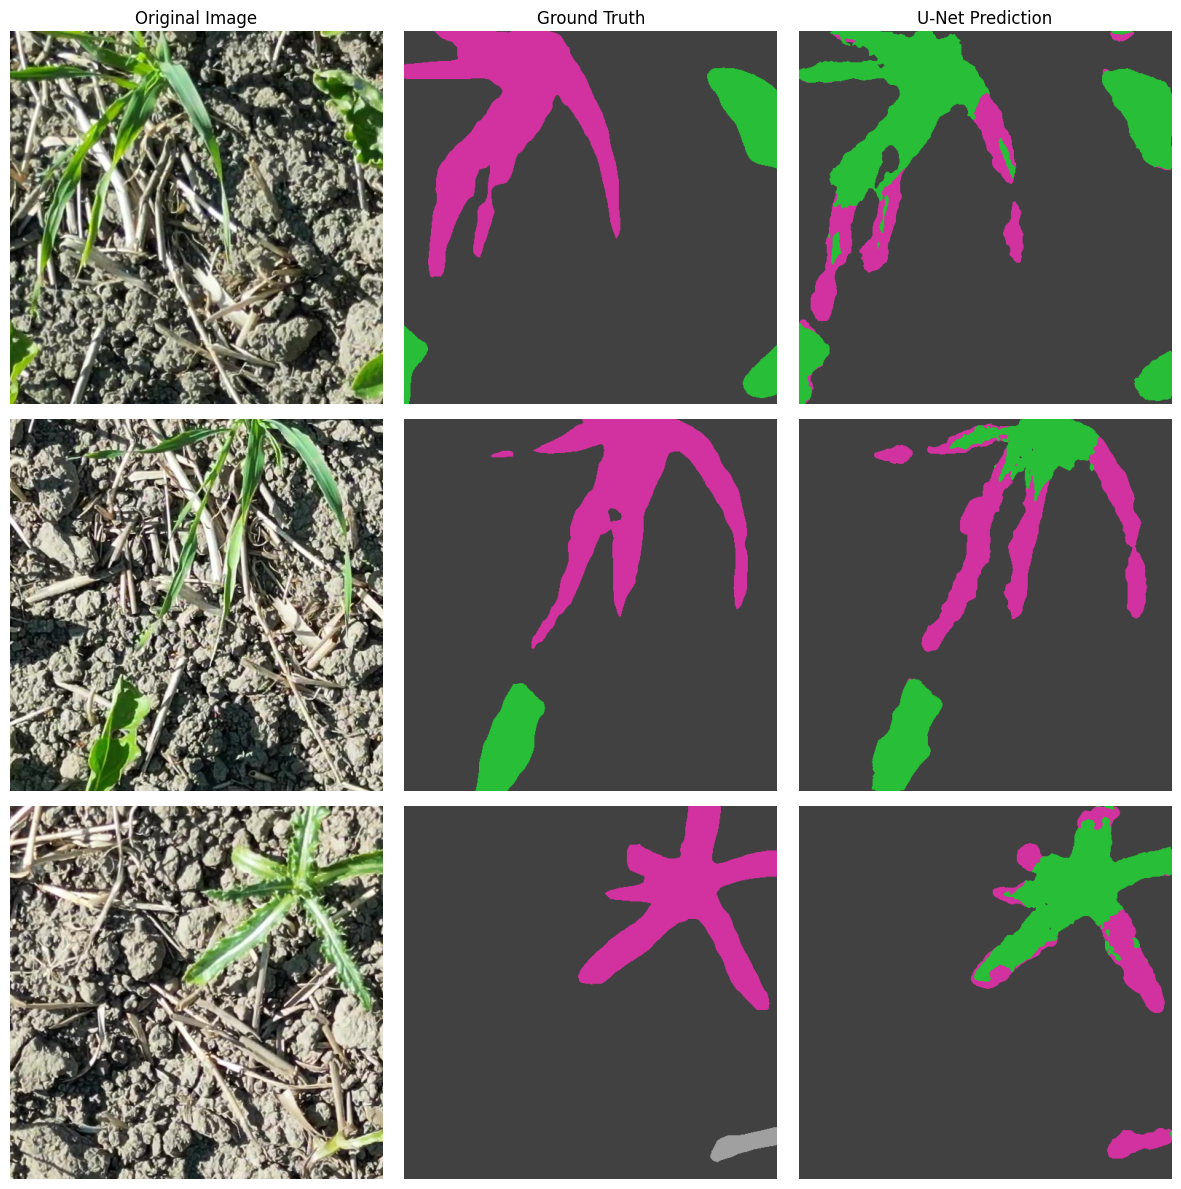

In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import defaultdict

# Load the best saved model
model.load_state_dict(
    torch.load(checkpoint_path,
               map_location=device,
               weights_only=True)
)
model.eval()

# Find weed-containing validation patches
by_mask = defaultdict(list)

for idx, (image_path, mask_path, x, y) in enumerate(val_dataset.samples):
    by_mask[mask_path].append((idx, x, y))

candidates = []

for mask_path, patches in by_mask.items():
    with Image.open(mask_path) as mask:
        arr = np.asarray(mask)

        for idx, x, y in patches:
            weed_pixels = np.count_nonzero(
                arr[y:y+512, x:x+512] == 2
            )
            if weed_pixels > 0:
                candidates.append((weed_pixels, idx))

# Select three examples with substantial weed coverage
selected = sorted(candidates, reverse=True)[:3]
assert len(selected) == 3

colors = {
    0: [65, 65, 65],
    1: [40, 190, 55],
    2: [210, 50, 160],
    255: [160, 160, 160]
}

def color_mask(mask):
    result = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for class_id, color in colors.items():
        result[mask == class_id] = color
    return result

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

with torch.inference_mode():
    for row, (_, idx) in enumerate(selected):
        image, mask = val_dataset[idx]

        prediction = model(
            image.unsqueeze(0).to(device)
        ).argmax(1)[0].cpu().numpy()

        axes[row, 0].imshow(
            image.permute(1, 2, 0).numpy()
        )
        axes[row, 1].imshow(
            color_mask(mask.numpy())
        )
        axes[row, 2].imshow(
            color_mask(prediction)
        )

        for ax in axes[row]:
            ax.axis("off")

for ax, title in zip(
    axes[0],
    ["Original Image", "Ground Truth", "U-Net Prediction"]
):
    ax.set_title(title)

plt.tight_layout()
plt.show()
